✅ Loaded operations: (375267, 5)
✅ Loaded merchants: (33852, 6)
✅ Loaded clients: (9249, 9)
Clients columns: ['client_id', 'account_number', 'full_name', 'date_of_birth', 'marital_status', 'gender', 'job_position', 'residence_location', 'age']

DATA QUALITY ISSUES – BEFORE CLEANING

Duplicates:
  Operations: 29607
  Merchants: 24305
  Clients: 0

Negative amounts (authorized_amount): 0

Placeholder names: 127
Placeholder jobs: 127

Underage clients (<18): 0
Clients with age > 120: 0

STARTING DATA CLEANING
Merchants: removed unnamed columns
Dropped duplicates from all datasets
Removed 88 negative amount rows
Capped transaction amounts at 99.9th percentile = 1500.00
Clients after age capping: 9249 (removed 0)
Standardised string formats

DATA QUALITY – AFTER CLEANING
Operations rows: 345572 (was 375267)
Merchants rows: 9546 (was 33852)
Clients rows: 9249 (was 9249)
Negative amounts left: 0
Underage clients left: 0
Clients >120 left: 0
Placeholder names left: 127


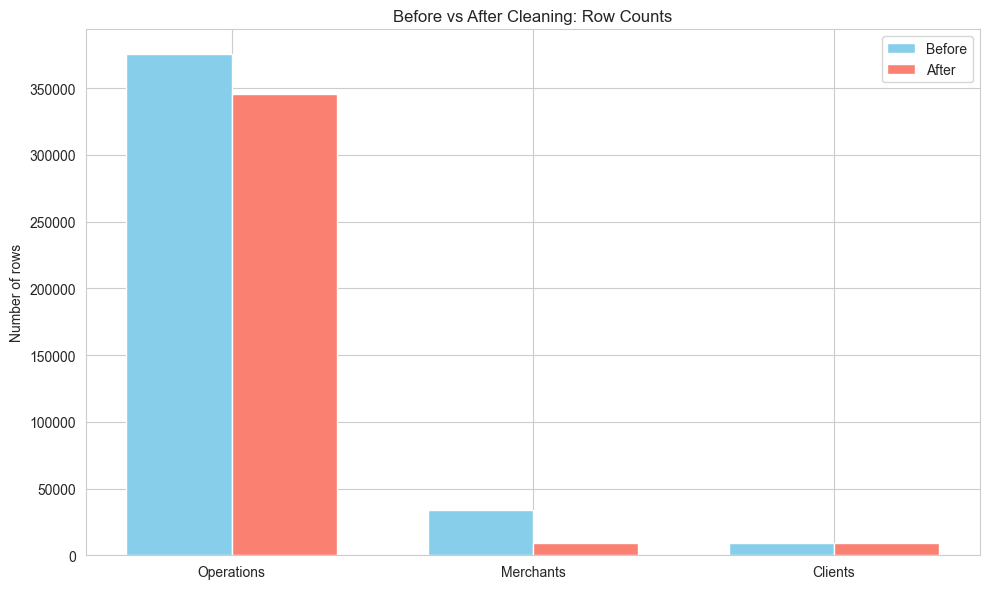

C:\Users\merie\AppData\Local\Temp\ipykernel_23000\1683154920.py:214: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Stage', y='Amount', data=melted, palette=['lightcoral', 'lightgreen'], ax=ax)


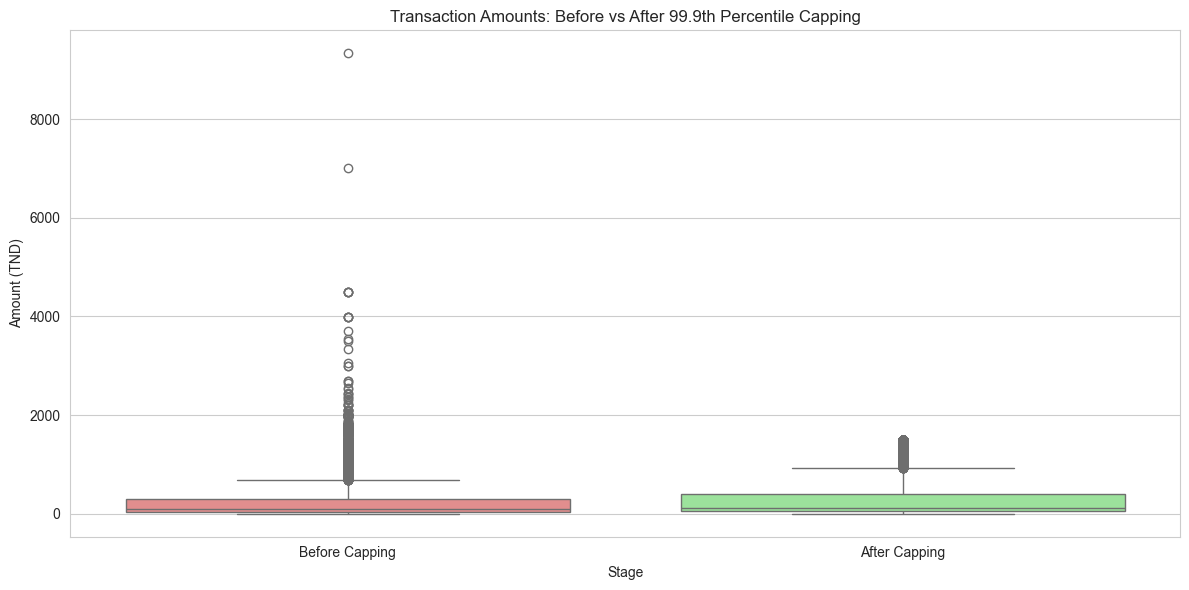

C:\Users\merie\AppData\Local\Temp\ipykernel_23000\1683154920.py:229: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\merie\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


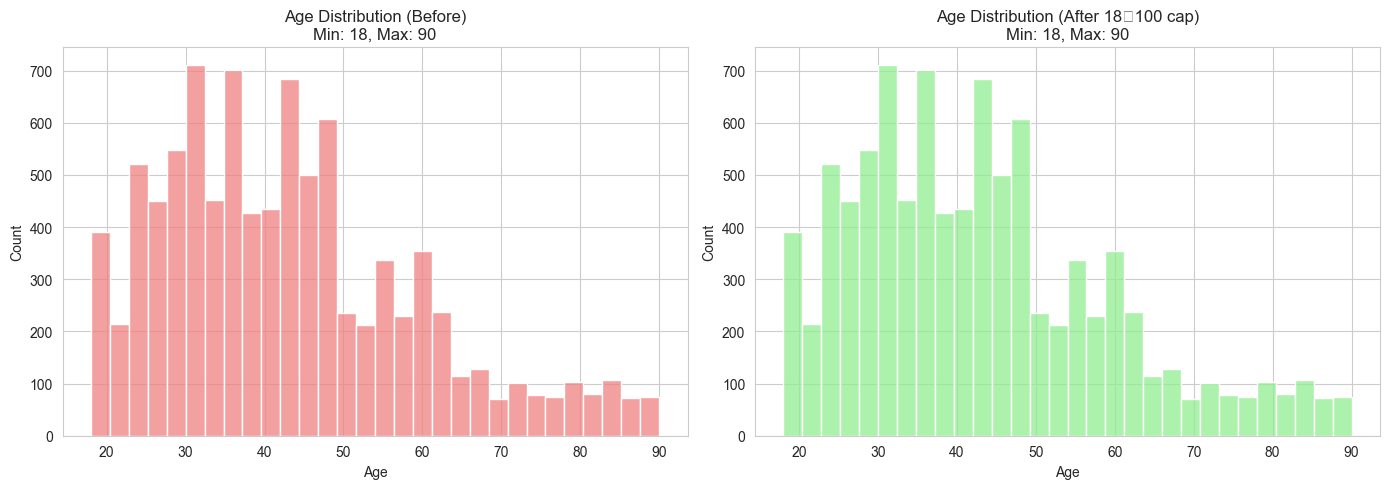

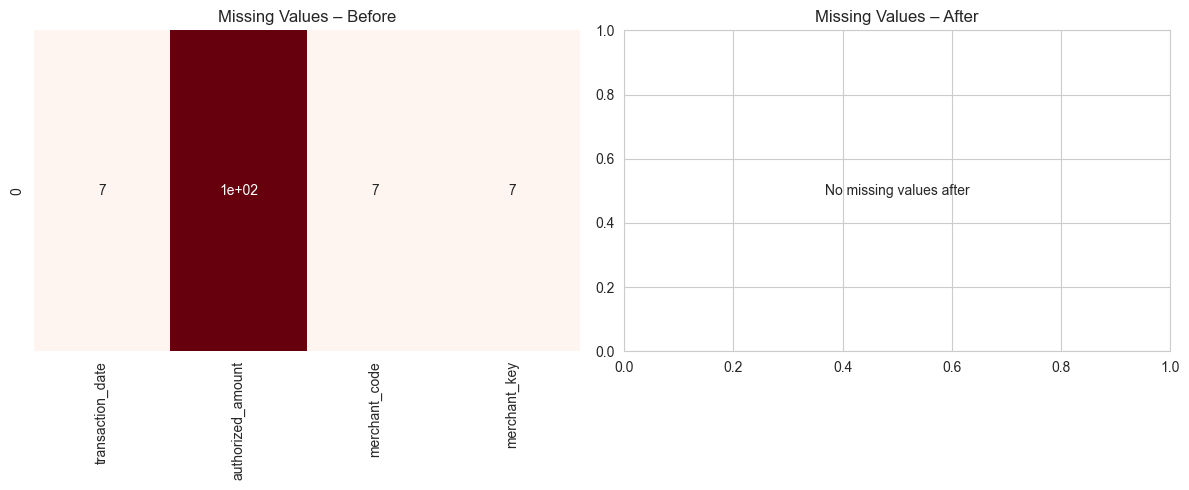

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# ============================================================
# 1. LOAD RAW DATA (with proper CSV handling)
# ============================================================

# Load operations (Excel)
operations = pd.read_excel('data/operations.xlsx')
print("✅ Loaded operations:", operations.shape)

# Load merchants (CSV, semicolon delimiter)
merchants = pd.read_csv('data/merchant.csv', delimiter=';', encoding='utf-8')
print("✅ Loaded merchants:", merchants.shape)

# Load clients (CSV with possible quoted fields – use pandas robust method)
clients = pd.read_csv('data/clients.csv', delimiter=',', quotechar='"', 
                      doublequote=True, encoding='utf-8', on_bad_lines='warn')
print("✅ Loaded clients:", clients.shape)

# If the above fails due to column count mismatch, try with engine='python' and skip bad lines
if clients.shape[1] < 5:  # crude check for failure
    clients = pd.read_csv('data/clients.csv', delimiter=',', quotechar='"',
                          engine='python', on_bad_lines='skip', encoding='utf-8')
    print("✅ Loaded clients with engine='python':", clients.shape)

# Show columns to verify
print("Clients columns:", list(clients.columns))

# ============================================================
# 2. SAVE RAW COPIES FOR BEFORE/AFTER COMPARISON
# ============================================================
operations_raw = operations.copy()
merchants_raw = merchants.copy()
clients_raw = clients.copy()
operations_before_cap = operations.copy()
clients_before_age = clients.copy()

# ============================================================
# 3. DETECT ISSUES BEFORE CLEANING
# ============================================================
print("\n" + "="*60)
print("DATA QUALITY ISSUES – BEFORE CLEANING")
print("="*60)

# ----- Duplicates -----
ops_dup = operations.duplicated().sum()
mer_dup = merchants.duplicated().sum()
cli_dup = clients.duplicated().sum()
print(f"\nDuplicates:\n  Operations: {ops_dup}\n  Merchants: {mer_dup}\n  Clients: {cli_dup}")

# ----- Negative amounts in operations -----
amount_col = 'authorized_amount'   # use the correct column name
for col in operations.columns:
    if 'amount' in col.lower() or 'montant' in col.lower() or 'authorized' in col.lower():
        amount_col = col
        break
if amount_col:
    neg_count = (operations[amount_col] < 0).sum()
    print(f"\nNegative amounts ({amount_col}): {neg_count}")
else:
    print("\nAmount column not found; please adjust column name detection.")

# ----- Placeholder names and jobs in clients -----
# Find name column
name_col = None
for col in clients.columns:
    if 'full_name' in col.lower() or 'name' in col.lower():
        name_col = col
        break
if name_col:
    placeholder_pattern = r'Client C\d+|Client C_\d+|Client Orphelin|^C\d{6}$'
    ph_names = clients[clients[name_col].astype(str).str.contains(placeholder_pattern, case=False, na=False)]
    print(f"\nPlaceholder names: {len(ph_names)}")
else:
    print("\nPlaceholder names: column 'full_name' not found. Columns:", list(clients.columns))

# Find job column
job_col = None
for col in clients.columns:
    if 'job' in col.lower() or 'profession' in col.lower():
        job_col = col
        break
if job_col:
    generic_jobs = ['professionnel', 'employé', 'unknown', 'n/a', 'nan', 'autre', 'indéfini']
    ph_jobs = clients[clients[job_col].astype(str).str.lower().isin(generic_jobs)]
    print(f"Placeholder jobs: {len(ph_jobs)}")
else:
    print("Placeholder jobs: column not found")

# ----- Underage clients and age >120 -----
age_col = None
for col in clients.columns:
    if col == 'age':
        age_col = col
        break
if age_col:
    clients[age_col] = pd.to_numeric(clients[age_col], errors='coerce')
    underage = (clients[age_col] < 18).sum()
    over_120 = (clients[age_col] > 120).sum()
    print(f"\nUnderage clients (<18): {underage}")
    print(f"Clients with age > 120: {over_120}")
else:
    print("\nAge column not found. Columns:", list(clients.columns))

# ============================================================
# 4. PERFORM CLEANING
# ============================================================
print("\n" + "="*60)
print("STARTING DATA CLEANING")
print("="*60)

# 4.1 Merchants: drop unnamed columns
merchants = merchants.loc[:, ~merchants.columns.str.contains('Unnamed', case=False)]
print("Merchants: removed unnamed columns")

# 4.2 Drop duplicates
operations = operations.drop_duplicates()
merchants = merchants.drop_duplicates()
clients = clients.drop_duplicates()
print("Dropped duplicates from all datasets")

# 4.3 Remove negative amounts from operations
if amount_col:
    before_neg = len(operations)
    operations = operations[operations[amount_col] >= 0]
    print(f"Removed {before_neg - len(operations)} negative amount rows")

# 4.4 Cap transaction amounts at 99.9th percentile (winsorize)
if amount_col:
    cap_value = operations[amount_col].quantile(0.999)
    operations[f'{amount_col}_capped'] = operations[amount_col].clip(upper=cap_value)
    operations[amount_col] = operations[f'{amount_col}_capped']
    print(f"Capped transaction amounts at 99.9th percentile = {cap_value:.2f}")

# 4.5 Clean age: cap between 18 and 100, remove >120
if age_col:
    before_age = len(clients)
    clients[age_col] = pd.to_numeric(clients[age_col], errors='coerce')
    clients[age_col] = clients[age_col].clip(lower=18, upper=100)
    clients = clients[clients[age_col] <= 120]
    print(f"Clients after age capping: {len(clients)} (removed {before_age - len(clients)})")

# 4.6 Handle missing values (simple imputation)
if job_col:
    clients[job_col] = clients[job_col].fillna('Unknown')
    clients[job_col] = clients[job_col].replace(['', 'nan', 'NaN'], 'Unknown')
if 'Category' in merchants.columns:
    merchants['Category'] = merchants['Category'].fillna('Other')

# 4.7 Standardise string formatting
if name_col:
    clients[name_col] = clients[name_col].astype(str).str.title()
if job_col:
    clients[job_col] = clients[job_col].astype(str).str.upper()
if 'gender' in clients.columns:
    clients['gender'] = clients['gender'].astype(str).str.upper()
if 'Category' in merchants.columns:
    merchants['Category'] = merchants['Category'].astype(str).str.upper()
print("Standardised string formats")

# ============================================================
# 5. AFTER CLEANING STATISTICS
# ============================================================
print("\n" + "="*60)
print("DATA QUALITY – AFTER CLEANING")
print("="*60)
print(f"Operations rows: {len(operations)} (was {len(operations_raw)})")
print(f"Merchants rows: {len(merchants)} (was {len(merchants_raw)})")
print(f"Clients rows: {len(clients)} (was {len(clients_raw)})")
if amount_col:
    print(f"Negative amounts left: {(operations[amount_col] < 0).sum()}")
if age_col:
    print(f"Underage clients left: {(clients[age_col] < 18).sum()}")
    print(f"Clients >120 left: {(clients[age_col] > 120).sum()}")
if name_col:
    ph_after = clients[clients[name_col].str.contains(placeholder_pattern, case=False, na=False)]
    print(f"Placeholder names left: {len(ph_after)}")

# ============================================================
# 6. BEFORE vs AFTER COMPARISONS (GRAPHS)
# ============================================================
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 6.1 Row counts bar chart
fig, ax = plt.subplots(figsize=(10,6))
datasets = ['Operations', 'Merchants', 'Clients']
before_counts = [len(operations_raw), len(merchants_raw), len(clients_raw)]
after_counts = [len(operations), len(merchants), len(clients)]
x = np.arange(len(datasets))
width = 0.35
ax.bar(x - width/2, before_counts, width, label='Before', color='skyblue')
ax.bar(x + width/2, after_counts, width, label='After', color='salmon')
ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.set_ylabel('Number of rows')
ax.set_title('Before vs After Cleaning: Row Counts')
ax.legend()
plt.tight_layout()
plt.show()

# 6.2 Boxplot of transaction amounts before/after capping (if amount_col)
if amount_col:
    comp_df = pd.DataFrame({
        'Before Capping': operations_before_cap[amount_col],
        'After Capping': operations[amount_col]
    })
    melted = comp_df.melt(var_name='Stage', value_name='Amount')
    fig, ax = plt.subplots(figsize=(12,6))
    sns.boxplot(x='Stage', y='Amount', data=melted, palette=['lightcoral', 'lightgreen'], ax=ax)
    ax.set_title('Transaction Amounts: Before vs After 99.9th Percentile Capping')
    ax.set_ylabel('Amount (TND)')
    plt.tight_layout()
    plt.show()

# 6.3 Age distribution before/after capping (if age_col)
if age_col:
    fig, axes = plt.subplots(1, 2, figsize=(14,5))
    sns.histplot(clients_before_age[age_col].dropna(), bins=30, ax=axes[0], color='lightcoral')
    axes[0].set_title(f'Age Distribution (Before)\nMin: {clients_before_age[age_col].min():.0f}, Max: {clients_before_age[age_col].max():.0f}')
    axes[0].set_xlabel('Age')
    sns.histplot(clients[age_col].dropna(), bins=30, ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Age Distribution (After 18‑100 cap)\nMin: {clients[age_col].min():.0f}, Max: {clients[age_col].max():.0f}')
    axes[1].set_xlabel('Age')
    plt.tight_layout()
    plt.show()

# 6.4 Missing values heatmap before/after (for operations)
missing_before = operations_raw.isnull().sum()
missing_before = missing_before[missing_before > 0]
missing_after = operations.isnull().sum()
missing_after = missing_after[missing_after > 0]

fig, axes = plt.subplots(1, 2, figsize=(12,5))
if not missing_before.empty:
    sns.heatmap(pd.DataFrame(missing_before).T, annot=True, cmap='Reds', cbar=False, ax=axes[0])
    axes[0].set_title('Missing Values – Before')
else:
    axes[0].text(0.5, 0.5, 'No missing values before', ha='center', va='center')
    axes[0].set_title('Missing Values – Before')
if not missing_after.empty:
    sns.heatmap(pd.DataFrame(missing_after).T, annot=True, cmap='Greens', cbar=False, ax=axes[1])
    axes[1].set_title('Missing Values – After')
else:
    axes[1].text(0.5, 0.5, 'No missing values after', ha='center', va='center')
    axes[1].set_title('Missing Values – After')
plt.tight_layout()
plt.show()

# ============================================================
# 7. SAVE CLEANED FILES
